# Member 3: PyTorch MLP Architecture Screening & 5-Fold 3-Seed Training

- **Objective:** Screen 3–4 layer `Linear + BatchNorm1d + ReLU + Dropout` PyTorch MLP architectures on Fold 0 using the locked imbalance config (`nn_imbalance_config.json`), then train the best architecture across 5 folds × 3 seeds (`[42, 2024, 2026]`).
- **Data Pipeline:** Strictly leak-free fold matrices from `nn_data_pipeline.py` (`train_folds.csv` & `test.csv`, 65 features).
- **Deliverables:** `nn_mlp_pipeline.py` (via `%%writefile`), `oof_nn.npy`, `test_nn.npy`, and `nn_final_metadata.json`.

## 1. Shared Module Export (`nn_mlp_pipeline.py`) & Locked Config Check

In [1]:
%%writefile nn_mlp_pipeline.py
"""Shared PyTorch MLP architecture training and 5-fold bagged inference pipeline for Member 3."""

import copy
from typing import Any

import numpy as np
import torch

from nn_data_pipeline import N_SPLITS, evaluate_auprc, iter_nn_folds
from nn_imbalance_pipeline import (
    FraudMLP,
    evaluate_binary_metrics,
    make_loss,
    predict_proba_tensor,
    set_seed,
)


def train_mlp_fold_with_test(
    fold_data: dict[str, Any],
    loss_cfg: dict[str, Any],
    arch_cfg: dict[str, Any],
    seed: int = 42,
    batch_size: int = 4096,
    max_epochs: int = 25,
    patience: int = 6,
    clip_val: float = 20.0,
    verbose: bool = False,
) -> tuple[np.ndarray, np.ndarray, float, dict[str, Any]]:
    """Train FraudMLP on one fold with outlier clipping, LR scheduling, and AUPRC early stopping."""
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    X_tr = np.clip(fold_data["X_train"], -clip_val, clip_val).astype(np.float32)
    X_va = np.clip(fold_data["X_val"], -clip_val, clip_val).astype(np.float32)
    X_te = np.clip(fold_data["X_test"], -clip_val, clip_val).astype(np.float32)
    y_tr = fold_data["y_train"].astype(np.float32)
    y_va = fold_data["y_val"].astype(np.int64)

    criterion, init_prior, _ = make_loss(
        loss_type=loss_cfg["loss_type"],
        y_train=fold_data["y_train"],
        device=device,
        pos_weight=loss_cfg.get("pos_weight_mode"),
        alpha=loss_cfg.get("alpha"),
        gamma=loss_cfg.get("gamma", 2.0) if loss_cfg.get("gamma") is not None else 2.0,
    )

    model = FraudMLP(
        in_features=X_tr.shape[1],
        hidden_dims=tuple(arch_cfg["hidden_dims"]),
        dropouts=tuple(arch_cfg["dropouts"]),
        init_pos_prob=init_prior,
    ).to(device)

    lr = float(arch_cfg.get("lr", 2e-3))
    weight_decay = float(arch_cfg.get("weight_decay", 1e-4))
    scheduler_type = arch_cfg.get("scheduler_type", "plateau")

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    if scheduler_type == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max_epochs, eta_min=1e-5
        )
    elif scheduler_type == "plateau":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=2
        )
    else:
        raise ValueError(f"Unsupported scheduler_type: {scheduler_type}")

    X_tr_t = torch.from_numpy(X_tr).to(device)
    y_tr_t = torch.from_numpy(y_tr).to(device)
    X_va_t = torch.from_numpy(X_va).to(device)
    X_te_t = torch.from_numpy(X_te).to(device)

    n_train = X_tr_t.shape[0]
    best_auprc = -1.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    no_improve = 0
    history: dict[str, Any] = {"train_loss": [], "val_auprc": []}

    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n_train, device=device)
        epoch_loss = 0.0
        seen = 0

        for start in range(0, n_train, batch_size):
            end = min(start + batch_size, n_train)
            if end - start < 2:
                continue
            idx = perm[start:end]
            optimizer.zero_grad(set_to_none=True)
            logits = model(X_tr_t[idx])
            loss = criterion(logits, y_tr_t[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            bs = end - start
            epoch_loss += float(loss.item()) * bs
            seen += bs

        avg_loss = epoch_loss / max(seen, 1)
        val_probs = predict_proba_tensor(model, X_va_t)
        val_auprc = evaluate_auprc(y_va, val_probs)

        if scheduler_type == "cosine":
            scheduler.step()
        else:
            scheduler.step(val_auprc)

        history["train_loss"].append(avg_loss)
        history["val_auprc"].append(val_auprc)

        if val_auprc > best_auprc + 1e-6:
            best_auprc = val_auprc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if verbose and (epoch == 1 or epoch % 5 == 0 or no_improve == 0):
            cur_lr = optimizer.param_groups[0]["lr"]
            print(
                f"  Epoch {epoch:02d}/{max_epochs} | loss={avg_loss:.5f} "
                f"| val_auprc={val_auprc:.5f} | lr={cur_lr:.2e}"
            )

        if no_improve >= patience:
            break

    model.load_state_dict(best_state)
    val_probs = predict_proba_tensor(model, X_va_t)
    test_probs = predict_proba_tensor(model, X_te_t)
    history["best_epoch"] = best_epoch
    return val_probs, test_probs, float(best_auprc), history


def run_bagged_mlp_cv(
    loss_cfg: dict[str, Any],
    arch_cfg: dict[str, Any],
    seeds: tuple[int, ...] = (42, 2024, 2026),
    train_folds_path: str = "train_folds.csv",
    test_path: str = "test.csv",
    batch_size: int = 4096,
    max_epochs: int = 25,
    patience: int = 6,
    clip_val: float = 20.0,
) -> dict[str, Any]:
    """Run 5-fold stratified CV with multi-seed bagging and return aligned OOF and test predictions."""
    oof_seeds: np.ndarray | None = None
    test_seeds: np.ndarray | None = None
    seed_fold_auprcs: dict[int, list[float]] = {int(s): [] for s in seeds}
    best_epochs: dict[int, list[int]] = {int(s): [] for s in seeds}

    for fold_k, fold_data in iter_nn_folds(train_folds_path, test_path):
        val_ids = fold_data["val_ids"]
        if oof_seeds is None:
            n_train = fold_data["X_train"].shape[0] + fold_data["X_val"].shape[0]
            n_test = fold_data["X_test"].shape[0]
            oof_seeds = np.zeros((len(seeds), n_train), dtype=np.float64)
            test_seeds = np.zeros((len(seeds), n_test), dtype=np.float64)

        for s_idx, seed in enumerate(seeds):
            val_p, test_p, best_ap, hist = train_mlp_fold_with_test(
                fold_data=fold_data,
                loss_cfg=loss_cfg,
                arch_cfg=arch_cfg,
                seed=int(seed) + fold_k,
                batch_size=batch_size,
                max_epochs=max_epochs,
                patience=patience,
                clip_val=clip_val,
                verbose=False,
            )
            oof_seeds[s_idx, val_ids] = val_p
            test_seeds[s_idx] += test_p / N_SPLITS
            seed_fold_auprcs[int(seed)].append(best_ap)
            best_epochs[int(seed)].append(int(hist["best_epoch"]))
            print(
                f"  Fold {fold_k} | Seed {seed} | val_auprc={best_ap:.5f} "
                f"(best_epoch={hist['best_epoch']})"
            )

    assert oof_seeds is not None and test_seeds is not None
    oof_nn = oof_seeds.mean(axis=0)
    test_nn = test_seeds.mean(axis=0)

    return {
        "oof_nn": oof_nn,
        "test_nn": test_nn,
        "oof_seeds": oof_seeds,
        "seed_fold_auprcs": seed_fold_auprcs,
        "best_epochs": best_epochs,
    }

Writing nn_mlp_pipeline.py


In [2]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import precision_recall_curve

from nn_data_pipeline import N_SPLITS, ensure_train_folds, evaluate_auprc, get_nn_fold_data
from nn_imbalance_pipeline import evaluate_binary_metrics
from nn_mlp_pipeline import run_bagged_mlp_cv, train_mlp_fold_with_test

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"PyTorch {torch.__version__} | CUDA={torch.cuda.is_available()} | Device: {device_name}")

with open("nn_imbalance_config.json", "r", encoding="utf-8") as f:
    imbalance_cfg = json.load(f)
print(
    f"Locked Imbalance Config: {imbalance_cfg['exp_id']} | {imbalance_cfg['strategy']} "
    f"| loss_type={imbalance_cfg['loss_type']} | pos_weight={imbalance_cfg['pos_weight_mode']}"
)

train_folds = ensure_train_folds("train_folds.csv", "train.csv")
fold0 = get_nn_fold_data(0, "train_folds.csv", "test.csv")
print(
    f"Fold 0 -> X_train: {fold0['X_train'].shape}, X_val: {fold0['X_val'].shape}, "
    f"X_test: {fold0['X_test'].shape} | NaNs: {np.isnan(fold0['X_train']).any()}"
)

PyTorch 2.6.0+cu124 | CUDA=True | Device: NVIDIA GeForce RTX 2050
Locked Imbalance Config: EXP-NN-1A | BCEWithLogits (pos_weight=1.0, Unweighted) | loss_type=bce | pos_weight=1.0


Fold 0 -> X_train: (559968, 65), X_val: (139992, 65), X_test: (299984, 65) | NaNs: False


## 2. Stage 1: MLP Architecture & Regularization Screening (Fold 0)
Compare 4 controlled 3–4 layer `Linear + BatchNorm1d + ReLU + Dropout` MLP variants on Fold 0 using the locked loss config.

[MLP-3L-Standard       ] AUPRC=0.48448 | ROC-AUC=0.94181 | BestF1=0.4841 (@th=0.200) | epoch=4 | 7.5s


[MLP-4L-Baseline       ] AUPRC=0.48336 | ROC-AUC=0.94142 | BestF1=0.4803 (@th=0.143) | epoch=8 | 7.5s


[MLP-4L-Wide           ] AUPRC=0.48478 | ROC-AUC=0.93999 | BestF1=0.4820 (@th=0.204) | epoch=12 | 16.4s


[MLP-4L-LightReg-Cosine] AUPRC=0.48158 | ROC-AUC=0.94071 | BestF1=0.4798 (@th=0.201) | epoch=4 | 5.3s


,Arch_ID,Layers,Dropouts,Scheduler,Val_AUPRC,Val_ROC_AUC,Best_F1,Best_Threshold,Best_Epoch,Time_Sec
0,MLP-4L-Wide,"[512, 256, 128, 64]","[0.35, 0.3, 0.2, 0.1]",plateau,0.48478,0.93999,0.48199,0.20369,12,16.4
1,MLP-3L-Standard,"[256, 128, 64]","[0.3, 0.2, 0.1]",plateau,0.48448,0.94181,0.48410,0.20047,4,7.5
2,MLP-4L-Baseline,"[256, 128, 64, 32]","[0.3, 0.25, 0.2, 0.1]",plateau,0.48336,0.94142,0.48031,0.14265,8,7.5
3,MLP-4L-LightReg-Cosine,"[256, 128, 64, 32]","[0.15, 0.15, 0.1, 0.05]",cosine,0.48158,0.94071,0.47983,0.20141,4,5.3


Selected Winning Architecture: MLP-4L-Wide -> {'arch_id': 'MLP-4L-Wide', 'hidden_dims': [512, 256, 128, 64], 'dropouts': [0.35, 0.3, 0.2, 0.1], 'lr': 0.0015, 'weight_decay': 0.0001, 'scheduler_type': 'plateau'}


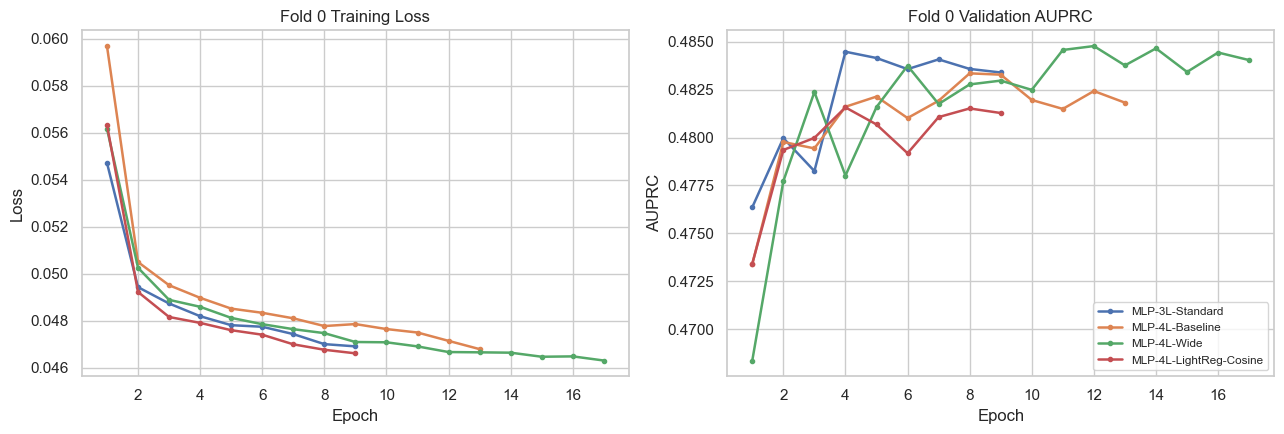

In [3]:
ARCH_CANDIDATES = [
    {
        "arch_id": "MLP-3L-Standard",
        "hidden_dims": [256, 128, 64],
        "dropouts": [0.30, 0.20, 0.10],
        "lr": 2e-3,
        "weight_decay": 1e-4,
        "scheduler_type": "plateau",
    },
    {
        "arch_id": "MLP-4L-Baseline",
        "hidden_dims": [256, 128, 64, 32],
        "dropouts": [0.30, 0.25, 0.20, 0.10],
        "lr": 2e-3,
        "weight_decay": 1e-4,
        "scheduler_type": "plateau",
    },
    {
        "arch_id": "MLP-4L-Wide",
        "hidden_dims": [512, 256, 128, 64],
        "dropouts": [0.35, 0.30, 0.20, 0.10],
        "lr": 1.5e-3,
        "weight_decay": 1e-4,
        "scheduler_type": "plateau",
    },
    {
        "arch_id": "MLP-4L-LightReg-Cosine",
        "hidden_dims": [256, 128, 64, 32],
        "dropouts": [0.15, 0.15, 0.10, 0.05],
        "lr": 2e-3,
        "weight_decay": 1e-4,
        "scheduler_type": "cosine",
    },
]

stage1_rows = []
stage1_histories = {}

for arch in ARCH_CANDIDATES:
    t0 = time.time()
    val_p, _, best_ap, hist = train_mlp_fold_with_test(
        fold_data=fold0,
        loss_cfg=imbalance_cfg,
        arch_cfg=arch,
        seed=42,
        batch_size=4096,
        max_epochs=25,
        patience=5,
        clip_val=float(imbalance_cfg.get("clip_val", 20.0)),
        verbose=False,
    )
    met = evaluate_binary_metrics(fold0["y_val"], val_p)
    elapsed = round(time.time() - t0, 1)
    stage1_histories[arch["arch_id"]] = hist
    stage1_rows.append({
        "Arch_ID": arch["arch_id"],
        "Layers": str(arch["hidden_dims"]),
        "Dropouts": str(arch["dropouts"]),
        "Scheduler": arch["scheduler_type"],
        "Val_AUPRC": met["auprc"],
        "Val_ROC_AUC": met["roc_auc"],
        "Best_F1": met["best_f1"],
        "Best_Threshold": met["best_threshold"],
        "Best_Epoch": hist["best_epoch"],
        "Time_Sec": elapsed,
    })
    print(
        f"[{arch['arch_id']:22s}] AUPRC={met['auprc']:.5f} | ROC-AUC={met['roc_auc']:.5f} "
        f"| BestF1={met['best_f1']:.4f} (@th={met['best_threshold']:.3f}) | epoch={hist['best_epoch']} | {elapsed:.1f}s"
    )

stage1_df = pd.DataFrame(stage1_rows).sort_values("Val_AUPRC", ascending=False).reset_index(drop=True)
display(stage1_df.round(5))

arch_lookup = {a["arch_id"]: a for a in ARCH_CANDIDATES}
winning_arch_id = stage1_df.iloc[0]["Arch_ID"]
winning_arch = arch_lookup[winning_arch_id]
print(f"Selected Winning Architecture: {winning_arch_id} -> {winning_arch}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for arch_id, hist in stage1_histories.items():
    epochs = range(1, len(hist["train_loss"]) + 1)
    axes[0].plot(epochs, hist["train_loss"], marker=".", lw=1.8, label=arch_id)
    axes[1].plot(epochs, hist["val_auprc"], marker=".", lw=1.8, label=arch_id)
axes[0].set_title("Fold 0 Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Fold 0 Validation AUPRC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUPRC")
axes[1].legend(fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()

## 3. Stage 2: Final 5-Fold Stratified CV + 3-Seed Bagging (`[42, 2024, 2026]`)
Train the winning `FraudMLP` configuration across all 5 folds and 3 random seeds to stabilize predictions and generate OOF/test probabilities.

In [4]:
SEEDS = [42, 2024, 2026]
t_cv_start = time.time()

cv_res = run_bagged_mlp_cv(
    loss_cfg=imbalance_cfg,
    arch_cfg=winning_arch,
    seeds=tuple(SEEDS),
    train_folds_path="train_folds.csv",
    test_path="test.csv",
    batch_size=4096,
    max_epochs=25,
    patience=6,
    clip_val=float(imbalance_cfg.get("clip_val", 20.0)),
)
train_time_sec = round(time.time() - t_cv_start, 2)

oof_nn = cv_res["oof_nn"]
test_nn = cv_res["test_nn"]
oof_seeds = cv_res["oof_seeds"]

y_true = train_folds["is_fraud"].to_numpy(dtype=np.int64)
folds_arr = train_folds["fold"].to_numpy(dtype=np.int64)

print("\nPer-Seed Overall OOF AUPRC:")
for idx, s in enumerate(SEEDS):
    print(f"  Seed {s}: OOF AUPRC = {evaluate_auprc(y_true, oof_seeds[idx]):.5f}")

nn_fold_auprcs = [
    evaluate_auprc(y_true[folds_arr == k], oof_nn[folds_arr == k])
    for k in range(N_SPLITS)
]
nn_metrics = evaluate_binary_metrics(y_true, oof_nn)

print("\n=== 3-Seed Bagged FraudMLP 5-Fold Summary ===")
for k, ap in enumerate(nn_fold_auprcs):
    print(f"  Fold {k} AUPRC: {ap:.5f}")
print(f"  Mean Fold AUPRC: {np.mean(nn_fold_auprcs):.5f} +/- {np.std(nn_fold_auprcs):.5f}")
print(f"  Overall OOF AUPRC: {nn_metrics['auprc']:.5f} | ROC-AUC: {nn_metrics['roc_auc']:.5f}")
print(
    f"  Best F1: {nn_metrics['best_f1']:.5f} @ Threshold={nn_metrics['best_threshold']:.4f} "
    f"| F1@0.50={nn_metrics['f1_at_050']:.5f}"
)
print(f"  Total CV Train Time: {train_time_sec}s")

  Fold 0 | Seed 42 | val_auprc=0.48478 (best_epoch=12)


  Fold 0 | Seed 2024 | val_auprc=0.48540 (best_epoch=16)


  Fold 0 | Seed 2026 | val_auprc=0.48478 (best_epoch=8)


  Fold 1 | Seed 42 | val_auprc=0.49782 (best_epoch=12)


  Fold 1 | Seed 2024 | val_auprc=0.49727 (best_epoch=11)


  Fold 1 | Seed 2026 | val_auprc=0.49795 (best_epoch=10)


... (7 outputs left out)

  Fold 4 | Seed 2024 | val_auprc=0.48328 (best_epoch=14)


  Fold 4 | Seed 2026 | val_auprc=0.48301 (best_epoch=15)

Per-Seed Overall OOF AUPRC:
  Seed 42: OOF AUPRC = 0.49218


  Seed 2024: OOF AUPRC = 0.49153
  Seed 2026: OOF AUPRC = 0.49326



=== 3-Seed Bagged FraudMLP 5-Fold Summary ===
  Fold 0 AUPRC: 0.48591
  Fold 1 AUPRC: 0.49868
  Fold 2 AUPRC: 0.50965
  Fold 3 AUPRC: 0.49360
  Fold 4 AUPRC: 0.48462
  Mean Fold AUPRC: 0.49449 +/- 0.00916
  Overall OOF AUPRC: 0.49383 | ROC-AUC: 0.94203
  Best F1: 0.48757 @ Threshold=0.2212 | F1@0.50=0.38535
  Total CV Train Time: 281.3s


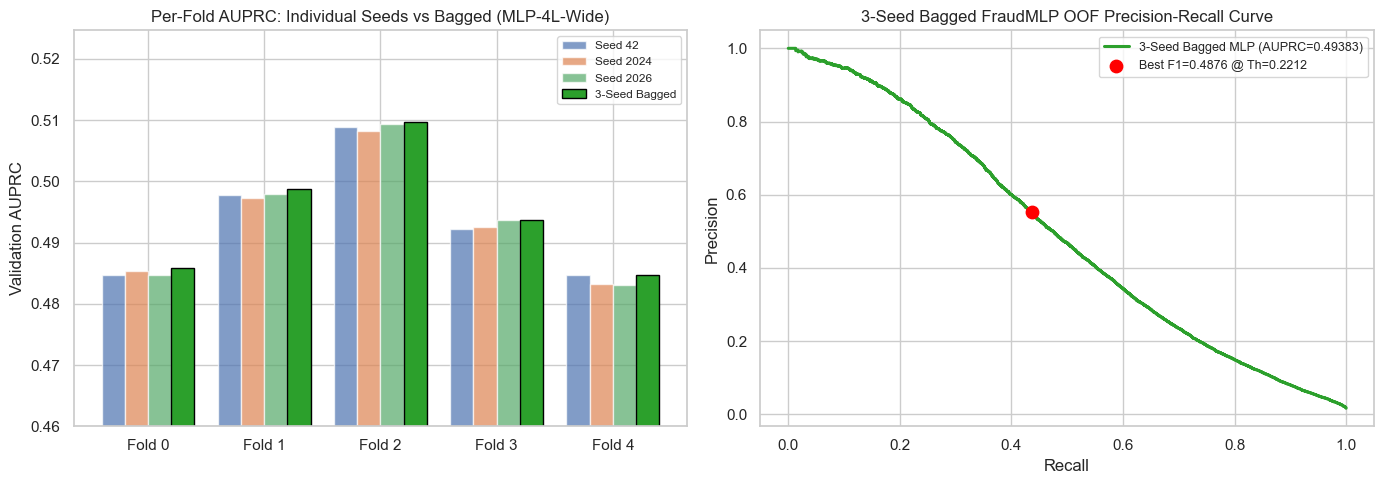

In [5]:
# Figure 2: Per-Fold AUPRC (Single Seeds vs Bagged) & OOF Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(N_SPLITS)
width = 0.2
for i, s in enumerate(SEEDS):
    axes[0].bar(x + (i - 1.5) * width, cv_res["seed_fold_auprcs"][s], width=width, alpha=0.7, label=f"Seed {s}")
axes[0].bar(x + 1.5 * width, nn_fold_auprcs, width=width, color="#2ca02c", edgecolor="black", label="3-Seed Bagged")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"Fold {k}" for k in range(N_SPLITS)])
axes[0].set_ylabel("Validation AUPRC")
axes[0].set_title(f"Per-Fold AUPRC: Individual Seeds vs Bagged ({winning_arch_id})")
axes[0].set_ylim(0.46, max(nn_fold_auprcs) + 0.015)
axes[0].legend(fontsize=8.5)

pr, rc, th = precision_recall_curve(y_true, oof_nn)
axes[1].plot(rc, pr, lw=2.2, color="#2ca02c", label=f"3-Seed Bagged MLP (AUPRC={nn_metrics['auprc']:.5f})")
idx_th = np.argmin(np.abs(th - nn_metrics["best_threshold"]))
axes[1].scatter(
    rc[idx_th], pr[idx_th], color="red", s=80, zorder=5,
    label=f"Best F1={nn_metrics['best_f1']:.4f} @ Th={nn_metrics['best_threshold']:.4f}"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("3-Seed Bagged FraudMLP OOF Precision-Recall Curve")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 4. Integrity Checks & Artifact Export (`oof_nn.npy`, `test_nn.npy`, `nn_final_metadata.json`)
Validate array shapes, probability bounds, exact ID alignment with `train_folds.csv` and `test.csv`, and preview prediction diversity against Member 2's `oof_lgbm.npy`.

In [6]:
test_raw_ids = pd.read_csv("test.csv", usecols=["id"])["id"].to_numpy(dtype=np.int64)
assert np.array_equal(train_folds["id"].to_numpy(dtype=np.int64), np.arange(len(train_folds))), "train_folds ID order mismatch!"
assert oof_nn.shape == (699960,), f"Unexpected oof_nn shape: {oof_nn.shape}"
assert test_nn.shape == (299984,), f"Unexpected test_nn shape: {test_nn.shape}"
assert len(test_raw_ids) == test_nn.shape[0]
assert not np.isnan(oof_nn).any() and not np.isinf(oof_nn).any()
assert not np.isnan(test_nn).any() and not np.isinf(test_nn).any()
assert (oof_nn >= 0.0).all() and (oof_nn <= 1.0).all()
assert (test_nn >= 0.0).all() and (test_nn <= 1.0).all()

oof_lgbm = np.load("oof_lgbm.npy")
assert oof_lgbm.shape == oof_nn.shape
p_corr = float(pearsonr(oof_lgbm, oof_nn).statistic)
s_corr = float(spearmanr(oof_lgbm, oof_nn).statistic)
print(f"Alignment OK | Diversity vs Member 2 oof_lgbm.npy -> Pearson r={p_corr:.4f}, Spearman rho={s_corr:.4f}")

np.save("oof_nn.npy", oof_nn)
np.save("test_nn.npy", test_nn)

nn_final_metadata = {
    "model": f"3-Seed Bagged {winning_arch_id} ({SEEDS})",
    "arch_id": winning_arch_id,
    "architecture": {
        "hidden_dims": winning_arch["hidden_dims"],
        "dropouts": winning_arch["dropouts"],
        "lr": winning_arch["lr"],
        "weight_decay": winning_arch["weight_decay"],
        "scheduler_type": winning_arch["scheduler_type"],
        "batch_size": 4096,
        "clip_val": float(imbalance_cfg.get("clip_val", 20.0)),
    },
    "imbalance_config": {
        "exp_id": imbalance_cfg["exp_id"],
        "loss_type": imbalance_cfg["loss_type"],
        "pos_weight_mode": imbalance_cfg["pos_weight_mode"],
        "alpha": imbalance_cfg["alpha"],
        "gamma": imbalance_cfg["gamma"],
    },
    "seeds": SEEDS,
    "oof_path": "oof_nn.npy",
    "test_path": "test_nn.npy",
    "oof_shape": list(oof_nn.shape),
    "test_shape": list(test_nn.shape),
    "oof_auprc": nn_metrics["auprc"],
    "mean_fold_auprc": float(np.mean(nn_fold_auprcs)),
    "std_fold_auprc": float(np.std(nn_fold_auprcs)),
    "oof_roc_auc": nn_metrics["roc_auc"],
    "f1_at_050": nn_metrics["f1_at_050"],
    "best_f1": nn_metrics["best_f1"],
    "best_threshold": nn_metrics["best_threshold"],
    "fold_auprcs": [float(v) for v in nn_fold_auprcs],
    "best_epochs_per_seed": cv_res["best_epochs"],
    "pearson_vs_lgbm": p_corr,
    "spearman_vs_lgbm": s_corr,
    "train_time_sec": train_time_sec,
}

with open("nn_final_metadata.json", "w", encoding="utf-8") as f:
    json.dump(nn_final_metadata, f, indent=2)

print("Exported: oof_nn.npy, test_nn.npy, nn_final_metadata.json")
print(json.dumps(nn_final_metadata, indent=2))

Alignment OK | Diversity vs Member 2 oof_lgbm.npy -> Pearson r=0.9061, Spearman rho=0.9319
Exported: oof_nn.npy, test_nn.npy, nn_final_metadata.json
{
  "model": "3-Seed Bagged MLP-4L-Wide ([42, 2024, 2026])",
  "arch_id": "MLP-4L-Wide",
  "architecture": {
    "hidden_dims": [
      512,
      256,
      128,
      64
    ],
    "dropouts": [
      0.35,
      0.3,
      0.2,
      0.1
    ],
    "lr": 0.0015,
    "weight_decay": 0.0001,
    "scheduler_type": "plateau",
    "batch_size": 4096,
    "clip_val": 20.0
  },
  "imbalance_config": {
    "exp_id": "EXP-NN-1A",
    "loss_type": "bce",
    "pos_weight_mode": 1.0,
    "alpha": null,
    "gamma": null
  },
  "seeds": [
    42,
    2024,
    2026
  ],
  "oof_path": "oof_nn.npy",
  "test_path": "test_nn.npy",
  "oof_shape": [
    699960
  ],
  "test_shape": [
    299984
  ],
  "oof_auprc": 0.4938326916464967,
  "mean_fold_auprc": 0.49449253008151733,
  "std_fold_auprc": 0.009157380883928277,
  "oof_roc_auc": 0.9420348018957614,
  "